# 04 Models

This notebook trains the Phase 2 models on the scaled train table from `03_preprocessing`. It tunes each model with cross validation grouped by repository on the train set only, so a repository never appears on both sides of a fold. The test set is not read until the final section, after the model and the threshold are chosen.

This part sets up the folds, tunes logistic regression, random forest and XGBoost, chooses the model and the threshold from the out of fold predictions, and saves the model for the hook. Only then do the last sections read the test set and score it once.

Outputs show counts and scores only, never `LineText` or `Value`, because the notebook is tracked by git.

## Setup

We import the libraries and set the paths. The notebook runs from the `notebooks` folder, so paths go up one level. One seed is used everywhere so the results can be repeated.

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import GroupKFold
from xgboost import XGBClassifier

DATA_DIR = Path("..") / "data" / "processed"
TRAIN_PATH = DATA_DIR / "features_train.csv"
OOF_PATH = DATA_DIR / "oof_scores.csv"
TEST_PATH = DATA_DIR / "features_test.csv"
CLEAN_PATH = DATA_DIR / "credata_clean.csv"
TEST_SCORES_PATH = DATA_DIR / "test_scores.csv"
MODEL_DIR = Path("..") / "models"

# The same seed as the split in 03_preprocessing
SEED = 65
N_FOLDS = 5
ID_COLS = ["Id", "RepoId", "GroundTruth", "label"]

## Load the train table

We read `features_train.csv` with `dtype=str` and `keep_default_na=False`, as agreed for every data file, and then turn the feature columns into numbers. The id columns stay as text. Only the train table is loaded here.

In [2]:
train = pd.read_csv(TRAIN_PATH, dtype=str, keep_default_na=False)
feature_cols = [c for c in train.columns if c not in ID_COLS]
X = train[feature_cols].astype(float)
y = train["label"].astype(int).to_numpy()
groups = train["RepoId"].to_numpy()

print("rows:", len(train))
print("repositories:", train["RepoId"].nunique())
print("feature columns:", len(feature_cols))
print("missing feature values:", int(X.isna().sum().sum()))
print("label 1 share:", round(y.mean() * 100, 2), "percent")

rows: 53056
repositories: 268
feature columns: 39
missing feature values: 0
label 1 share: 23.36 percent


The train table has 53,056 rows from 268 repositories, 39 features with no missing values and 23.36 percent real secrets, the same numbers `03_preprocessing` saved.

## Feature sets

`docs/DECISIONS.md` asks for results with and without `value_empty`, because B flagged it as a possible leak of how rows were labeled, and the hook cannot rebuild it from a raw line. The hook also finds values in a different way from the annotators, so we keep a third set with line and path features only, as the fallback in `docs/PHASE2_PLAN.md` says. Every model is tuned on all three sets.

In [3]:
value_cols = [c for c in feature_cols if c.startswith("value_")]
FEATURE_SETS = {
    "all": feature_cols,
    "no_value_empty": [c for c in feature_cols if c != "value_empty"],
    "line_and_path": [c for c in feature_cols if c not in value_cols],
}
print("value features:", value_cols)
for name, cols in FEATURE_SETS.items():
    print(name, len(cols), "columns")

value features: ['value_len', 'value_empty', 'value_entropy', 'value_digit_ratio', 'value_upper_ratio', 'value_lower_ratio', 'value_symbol_ratio']
all 39 columns
no_value_empty 38 columns
line_and_path 32 columns


## Folds grouped by repository

`GroupKFold` puts all rows of a repository in the same fold, so each fold is scored on repositories the model has not seen, just like the test set. We check that no repository is on both sides of any fold, and look at the size and label share of each fold, because `01_cleaning` found that one repository holds 15.4 percent of all rows.

In [4]:
folds = list(GroupKFold(n_splits=N_FOLDS).split(X, y, groups))
fold_rows = []
for i, (tr, va) in enumerate(folds):
    fold_rows.append({
        "fold": i,
        "valid_repositories": len(set(groups[va])),
        "valid_rows": len(va),
        "valid_rows_percent": round(len(va) / len(y) * 100, 2),
        "valid_label_1_percent": round(y[va].mean() * 100, 2),
        "repositories_on_both_sides": len(set(groups[tr]) & set(groups[va])),
    })
print(pd.DataFrame(fold_rows).to_string(index=False))

 fold  valid_repositories  valid_rows  valid_rows_percent  valid_label_1_percent  repositories_on_both_sides
    0                  20       10612                20.0                  49.58                           0
    1                  54       10611                20.0                  11.04                           0
    2                  65       10611                20.0                  14.29                           0
    3                  65       10611                20.0                  23.39                           0
    4                  64       10611                20.0                  18.49                           0


No repository is on both sides of any fold, and every fold holds 20 percent of rows. The label share is very uneven: fold 0 has only 20 repositories but 49.58 percent real secrets, because it holds the largest repository, while fold 1 has 11.04 percent. Scores will therefore differ a lot between folds, and the standard deviation matters as much as the mean.

## How models are scored

Real secrets are about 23 percent of rows, so accuracy would look good for a model that never flags anything. The main score is average precision, the area under the precision recall curve, which looks only at how well real secrets are ranked above false alarms and does not need a threshold. ROC AUC and F1 at a threshold of 0.5 are shown next to it. The threshold itself is chosen later from the out of fold predictions, never from the test set.

For each fold we train on the other four folds and score the held out fold. The tables show the mean and the standard deviation over the five folds. Each model is built from the labels of its training folds only, so class weights never use the held out fold.

In [5]:
def cross_validate(make_model, cols):
    # Trains one model per fold and returns the fold scores and the out of fold scores
    oof = np.zeros(len(y))
    scores = []
    for tr, va in folds:
        model = make_model(y[tr])
        model.fit(X.iloc[tr][cols], y[tr])
        p = model.predict_proba(X.iloc[va][cols])[:, 1]
        oof[va] = p
        scores.append({
            "ap": average_precision_score(y[va], p),
            "roc_auc": roc_auc_score(y[va], p),
            "f1_at_half": f1_score(y[va], (p >= 0.5).astype(int)),
        })
    return pd.DataFrame(scores), oof


def summarize(scores):
    # Mean and standard deviation of each score over the folds
    out = {}
    for col in scores.columns:
        out[col + "_mean"] = round(scores[col].mean(), 4)
        out[col + "_std"] = round(scores[col].std(), 4)
    return out

## Logistic regression

Logistic regression is the simplest of the three models and needs scaled inputs, which `03_preprocessing` already gives. `class_weight="balanced"` gives real secrets more weight in training so the model does not ignore the smaller class. We try four values of `C`, the inverse of the regularization strength, on each feature set.

In [6]:
C_GRID = [0.01, 0.1, 1.0, 10.0]


def make_logreg(C):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=5000, random_state=SEED)


results = []
oof_scores = {}
fold_tables = {}
for set_name, cols in FEATURE_SETS.items():
    for C in C_GRID:
        scores, oof = cross_validate(lambda y_tr: make_logreg(C), cols)
        results.append({"feature_set": set_name, "C": C, **summarize(scores)})
        oof_scores[(set_name, C)] = oof
        fold_tables[(set_name, C)] = scores

lr_results = pd.DataFrame(results)
print(lr_results.to_string(index=False))

   feature_set     C  ap_mean  ap_std  roc_auc_mean  roc_auc_std  f1_at_half_mean  f1_at_half_std
           all  0.01   0.7205  0.1903        0.9179       0.0595           0.6642          0.2095
           all  0.10   0.7458  0.1607        0.9330       0.0425           0.6912          0.1760
           all  1.00   0.7481  0.1532        0.9371       0.0373           0.7097          0.1469
           all 10.00   0.7476  0.1519        0.9378       0.0365           0.7111          0.1434
no_value_empty  0.01   0.7210  0.1897        0.9180       0.0593           0.6643          0.2096
no_value_empty  0.10   0.7465  0.1600        0.9332       0.0421           0.6933          0.1725
no_value_empty  1.00   0.7487  0.1533        0.9371       0.0375           0.7083          0.1478
no_value_empty 10.00   0.7475  0.1523        0.9378       0.0366           0.7104          0.1455
 line_and_path  0.01   0.4772  0.2215        0.7664       0.0353           0.4613          0.0863
 line_and_path  0.10

On all features, `C` of 1 and 10 give almost the same average precision (0.748), and only the strongest regularization (`C` 0.01) is clearly worse. Removing `value_empty` changes nothing (0.7487 against 0.7481). This does not prove the model ignores how rows were labeled, because `value_len` and the value ratios are 0 on exactly the same rows, so the same information is still there. Line and path features alone reach only 0.497, so the value features carry most of the signal, as `02_eda` suggested.

## Best setting for each feature set

For each feature set we keep the `C` with the highest mean average precision.

In [7]:
best = lr_results.loc[lr_results.groupby("feature_set", sort=False)["ap_mean"].idxmax()]
print(best[["feature_set", "C", "ap_mean", "ap_std", "roc_auc_mean", "f1_at_half_mean"]].to_string(index=False))

   feature_set    C  ap_mean  ap_std  roc_auc_mean  f1_at_half_mean
           all  1.0   0.7481  0.1532        0.9371           0.7097
no_value_empty  1.0   0.7487  0.1533        0.9371           0.7083
 line_and_path 10.0   0.4966  0.2313        0.7888           0.4722


The best settings are `C` 1 for all features and for no `value_empty`, and `C` 10 for line and path features. The gap between the value based sets and the line and path set is about 0.25 in average precision and 0.15 in ROC AUC.

## Scores by fold

The mean can hide one fold that behaves very differently, for example the fold that holds the largest repository. We print the fold scores of the best setting on each feature set.

In [8]:
for _, row in best.iterrows():
    table = fold_tables[(row["feature_set"], row["C"])].copy()
    table.insert(0, "fold", range(N_FOLDS))
    print(row["feature_set"], "with C", row["C"])
    print(table.round(4).to_string(index=False))
    print()

all with C 1.0
 fold     ap  roc_auc  f1_at_half
    0 0.9854   0.9894      0.9156
    1 0.5890   0.8871      0.5096
    2 0.6841   0.9446      0.7016
    3 0.8043   0.9430      0.7541
    4 0.6776   0.9213      0.6673

no_value_empty with C 1.0
 fold     ap  roc_auc  f1_at_half
    0 0.9854   0.9893      0.9141
    1 0.5878   0.8862      0.5052
    2 0.6845   0.9447      0.7018
    3 0.8061   0.9428      0.7535
    4 0.6799   0.9222      0.6672

line_and_path with C 10.0
 fold     ap  roc_auc  f1_at_half
    0 0.8453   0.8585      0.5602
    1 0.3269   0.7817      0.3811
    2 0.3062   0.7403      0.3957
    3 0.6192   0.8124      0.5924
    4 0.3856   0.7512      0.4314



Fold 0, which holds the largest repository, scores 0.985 average precision, far above the other folds (0.59 to 0.81). The mean over folds is pulled up by this one repository, so the fairer picture of logistic regression on unseen repositories is the four other folds. The line and path model drops the most on folds 1, 2 and 4.

## Largest weights

The weights of logistic regression show which features push a row toward a real secret. All numeric features are on the same scale and the flags are 0 or 1, so the sizes are roughly comparable. We fit the best setting on all features on the whole train set and print the largest weights in each direction.

In [9]:
best_all_C = float(best.loc[best["feature_set"] == "all", "C"].iloc[0])
full = make_logreg(best_all_C)
full.fit(X[FEATURE_SETS["all"]], y)
weights = pd.Series(full.coef_[0], index=FEATURE_SETS["all"]).sort_values()
print("toward label 0")
print(weights.head(8).round(3).to_string())
print()
print("toward label 1")
print(weights.tail(8).round(3).to_string())

toward label 0
line_has_key         -2.951
value_symbol_ratio   -1.267
line_has_auth        -0.964
var_name_len         -0.875
ext_other            -0.862
value_empty          -0.847
line_has_password    -0.809
ext_keyfile          -0.798

toward label 1
line_has_assign        1.079
name_has_secret        1.153
path_has_doc           1.461
name_has_key           1.753
name_has_password      1.802
value_entropy          3.351
line_has_key_header    6.637
multi_line             8.211


The largest weights toward a real secret are `multi_line` (8.21) and `line_has_key_header` (6.64), which fits the private key blocks that span several lines, followed by `value_entropy` (3.35). The hook only sees one added line at a time, so it cannot see a multi line label in the same way, which is one more reason to compare the feature sets. `line_has_key` pushes strongly toward a false alarm (minus 2.95), while `name_has_key` pushes toward a real secret (1.75), so where the keyword appears matters more than whether it appears.

## Random forest

A random forest averages many decision trees, each grown on a random sample of rows and features, so it can find interactions such as a keyword that only matters in a certain file type. Trees do not need scaled inputs, but the scaled table gives the same splits, so the same table serves all three models. `class_weight="balanced"` gives real secrets more weight, as in logistic regression.

One forest of 200 trees takes about 20 seconds on four folds of train, so the grid is kept small: no depth limit or a depth of 20, and at least 1 or 5 rows in each leaf. Larger leaves and a depth limit make the trees simpler and less likely to learn single repositories by heart.

In [10]:
RF_GRID = [{"max_depth": d, "min_samples_leaf": leaf} for d in [None, 20] for leaf in [1, 5]]


def make_forest(params):
    return RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=SEED, **params)


rf_rows = []
rf_oof = {}
for set_name, cols in FEATURE_SETS.items():
    for i, params in enumerate(RF_GRID):
        scores, oof = cross_validate(lambda y_tr: make_forest(params), cols)
        # A missing depth limit is written as none so the tables stay readable
        shown = {"max_depth": params["max_depth"] or "none", "min_samples_leaf": params["min_samples_leaf"]}
        rf_rows.append({"feature_set": set_name, "setting": i, **shown, **summarize(scores)})
        rf_oof[(set_name, i)] = oof

rf_results = pd.DataFrame(rf_rows)
print(rf_results.drop(columns=["roc_auc_std", "f1_at_half_std"]).to_string(index=False))

   feature_set  setting max_depth  min_samples_leaf  ap_mean  ap_std  roc_auc_mean  f1_at_half_mean
           all        0      none                 1   0.9075  0.0577        0.9762           0.8549
           all        1      none                 5   0.9002  0.0608        0.9730           0.7677
           all        2        20                 1   0.9087  0.0566        0.9769           0.8589
           all        3        20                 5   0.9020  0.0565        0.9738           0.7582
no_value_empty        0      none                 1   0.9048  0.0628        0.9747           0.8486
no_value_empty        1      none                 5   0.9034  0.0593        0.9743           0.7604
no_value_empty        2        20                 1   0.9071  0.0595        0.9765           0.8599
no_value_empty        3        20                 5   0.9011  0.0609        0.9736           0.7588
 line_and_path        0      none                 1   0.5423  0.1935        0.8171           0.3446


The random forest is far ahead of logistic regression: 0.9087 average precision on all features against 0.7481, with a much smaller spread over folds (0.057 against 0.153). The four settings are within 0.009 of each other, and a depth of 20 with leaves of 1 row is best on every feature set. Leaves of 5 rows lower F1 at 0.5 by 0.09 to 0.10 while average precision barely moves, which means they shift the scores rather than the ranking, something the threshold step will correct. On line and path features only, the forest reaches 0.5526, better than logistic regression (0.4966) but still far below the sets with value features.

## XGBoost

XGBoost grows trees one after another, each one fixing the mistakes of the trees before it. Its class weight is `scale_pos_weight`, the number of label 0 rows divided by the number of label 1 rows, worked out on the training folds of each split. The grid tries a tree depth of 4 or 6 and a learning rate of 0.05 or 0.1, with 300 trees and the fast histogram method.

In [11]:
XGB_GRID = [{"max_depth": d, "learning_rate": lr} for d in [4, 6] for lr in [0.05, 0.1]]


def make_xgb(params, y_tr):
    weight = (y_tr == 0).sum() / (y_tr == 1).sum()
    return XGBClassifier(n_estimators=300, tree_method="hist", scale_pos_weight=weight,
                         n_jobs=-1, random_state=SEED, **params)


xgb_rows = []
xgb_oof = {}
for set_name, cols in FEATURE_SETS.items():
    for i, params in enumerate(XGB_GRID):
        scores, oof = cross_validate(lambda y_tr: make_xgb(params, y_tr), cols)
        xgb_rows.append({"feature_set": set_name, "setting": i, **params, **summarize(scores)})
        xgb_oof[(set_name, i)] = oof

xgb_results = pd.DataFrame(xgb_rows)
print(xgb_results.drop(columns=["roc_auc_std", "f1_at_half_std"]).to_string(index=False))

   feature_set  setting  max_depth  learning_rate  ap_mean  ap_std  roc_auc_mean  f1_at_half_mean
           all        0          4           0.05   0.8914  0.0500        0.9720           0.8332
           all        1          4           0.10   0.8835  0.0608        0.9689           0.7760
           all        2          6           0.05   0.9037  0.0329        0.9706           0.8337
           all        3          6           0.10   0.9072  0.0325        0.9714           0.8331
no_value_empty        0          4           0.05   0.8914  0.0500        0.9720           0.8332
no_value_empty        1          4           0.10   0.8835  0.0608        0.9689           0.7760
no_value_empty        2          6           0.05   0.9037  0.0329        0.9706           0.8337
no_value_empty        3          6           0.10   0.9072  0.0325        0.9714           0.8331
 line_and_path        0          4           0.05   0.5251  0.1455        0.7757           0.4920
 line_and_path      

XGBoost on all features reaches 0.9072 average precision with a depth of 6 and a learning rate of 0.1, almost the same as the random forest, but with the smallest spread over folds of any model (0.033). The deeper trees score higher at both learning rates, and the best setting sits at the edge of the grid. The scores with and without `value_empty` are identical to four decimals, because a tree can split `value_len` at 0 and find exactly the same rows. On line and path features only, XGBoost reaches 0.5399.

## The three models side by side

For each model and feature set we keep the setting with the highest mean average precision and put them in one table. The model and threshold for the test set are chosen from this table and the out of fold predictions in the next section.

In [12]:
def best_rows(results, model_name, key_cols):
    rows = results.loc[results.groupby("feature_set", sort=False)["ap_mean"].idxmax()].copy()
    rows["setting_used"] = rows[key_cols].astype(str).agg(", ".join, axis=1)
    rows.insert(0, "model", model_name)
    return rows


lr_named = lr_results.copy()
lr_named["setting"] = lr_named["C"]
comparison = pd.concat([
    best_rows(lr_named, "logreg", ["C"]),
    best_rows(rf_results, "random_forest", ["max_depth", "min_samples_leaf"]),
    best_rows(xgb_results, "xgboost", ["max_depth", "learning_rate"]),
])
show = ["model", "feature_set", "setting_used", "ap_mean", "ap_std", "roc_auc_mean", "f1_at_half_mean"]
print(comparison.sort_values(["feature_set", "ap_mean"], ascending=[True, False])[show].to_string(index=False))

        model    feature_set setting_used  ap_mean  ap_std  roc_auc_mean  f1_at_half_mean
random_forest            all        20, 1   0.9087  0.0566        0.9769           0.8589
      xgboost            all       6, 0.1   0.9072  0.0325        0.9714           0.8331
       logreg            all          1.0   0.7481  0.1532        0.9371           0.7097
random_forest  line_and_path        20, 1   0.5526  0.1831        0.8301           0.3820
      xgboost  line_and_path       4, 0.1   0.5399  0.1521        0.8055           0.5093
       logreg  line_and_path         10.0   0.4966  0.2313        0.7888           0.4722
      xgboost no_value_empty       6, 0.1   0.9072  0.0325        0.9714           0.8331
random_forest no_value_empty        20, 1   0.9071  0.0595        0.9765           0.8599
       logreg no_value_empty          1.0   0.7487  0.1533        0.9371           0.7083


Both tree models beat logistic regression by about 0.16 in average precision on the value based sets, so the interactions between features matter. Random forest and XGBoost are within 0.0015 of each other, which is much less than their spread over folds, so average precision alone does not separate them. XGBoost has the smaller spread over folds (0.033 against 0.057), and the random forest has the higher F1 at 0.5 (0.859 against 0.833) before any threshold tuning. Dropping `value_empty` costs at most 0.0016 for any model. On line and path features only, both tree models lose more than 0.35 and logistic regression loses 0.25, so the value features carry most of what the models learn, and a hook that cannot find the value the way annotators did would lose much of this skill.

## Save the out of fold predictions

The threshold is chosen from out of fold predictions, so we save them for the best setting of each model and feature set. The file holds ids and scores only, no line text, and it stays in `data/processed`, which git ignores.

In [13]:
oof_store = {"logreg": oof_scores, "random_forest": rf_oof, "xgboost": xgb_oof}
oof_table = train[ID_COLS].copy()
for _, row in comparison.iterrows():
    key = (row["feature_set"], row["setting"])
    oof_table[row["model"] + "_" + row["feature_set"]] = oof_store[row["model"]][key]
oof_table.to_csv(OOF_PATH, index=False, lineterminator="\n")
print("saved", OOF_PATH.name, "with", len(oof_table), "rows and score columns")
print(list(oof_table.columns[len(ID_COLS):]))

saved oof_scores.csv with 53056 rows and score columns
['logreg_all', 'logreg_no_value_empty', 'logreg_line_and_path', 'random_forest_all', 'random_forest_no_value_empty', 'random_forest_line_and_path', 'xgboost_all', 'xgboost_no_value_empty', 'xgboost_line_and_path']


## Choose the model

The rules are fixed here, before any test score exists, and they use only the out of fold results above.

- The model for the hook uses the feature set without `value_empty`, because the hook cannot rebuild it from a raw line (see `docs/DECISIONS.md`).
- A second model with line and path features only is saved in the same format, as the fallback in `docs/PHASE2_PLAN.md` for the case where the hook cannot find values well.
- Within each feature set the model with the highest mean average precision wins. When another model is within 0.005 of it, which is far less than the spread over folds, the one with the smaller standard deviation over folds wins, because it is more stable on unseen repositories.

In [14]:
TIE = 0.005
HOOK_SET = "no_value_empty"
FALLBACK_SET = "line_and_path"


def choose(set_name):
    rows = comparison[comparison["feature_set"] == set_name]
    close = rows[rows["ap_mean"] >= rows["ap_mean"].max() - TIE]
    return close.sort_values("ap_std").iloc[0]


chosen = {s: choose(s) for s in [HOOK_SET, FALLBACK_SET]}
for set_name, row in chosen.items():
    print(set_name, "chosen:", row["model"], "with", row["setting_used"],
          "average precision", row["ap_mean"], "std", row["ap_std"])

no_value_empty chosen: xgboost with 6, 0.1 average precision 0.9072 std 0.0325
line_and_path chosen: random_forest with 20, 1 average precision 0.5526 std 0.1831


Without `value_empty`, XGBoost (depth 6, learning rate 0.1) wins with 0.9072 average precision. The random forest is only 0.0001 behind, so the tie rule applies, and XGBoost has the smaller spread over folds (0.033 against 0.060). It is also a much smaller file for the hook to load. On line and path features only, the random forest is 0.013 ahead of XGBoost, outside the tie margin, so it is the fallback model.

## Choose the threshold

The rule is fixed before any test score exists: the threshold is the score that gives the highest F1 on the pooled out of fold predictions of the chosen model. F1 weighs missed secrets and false alarms equally, which suits a hook that must catch secrets without blocking so many commits that developers turn it off. We also print precision, recall and F1 at 0.5 for comparison, and the F1 of each fold at the chosen threshold to see how stable it is.

In [15]:
def best_f1_threshold(scores):
    precision, recall, thresholds = precision_recall_curve(y, scores)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    # The last precision and recall pair has no threshold, so it is left out
    i = int(np.argmax(f1[:-1]))
    return float(thresholds[i]), precision[i], recall[i], f1[i]


def precision_recall_at(scores, threshold, labels):
    flagged = scores >= threshold
    tp = (flagged & (labels == 1)).sum()
    precision = tp / max(flagged.sum(), 1)
    recall = tp / max((labels == 1).sum(), 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    return precision, recall, f1


thresholds = {}
for set_name, row in chosen.items():
    scores = oof_table[row["model"] + "_" + set_name].to_numpy()
    t, p, r, f = best_f1_threshold(scores)
    thresholds[set_name] = t
    p5, r5, f5 = precision_recall_at(scores, 0.5, y)
    print(set_name, row["model"])
    print("  best F1 threshold", round(t, 4), "precision", round(p, 4), "recall", round(r, 4), "F1", round(f, 4))
    print("  at 0.5            precision", round(p5, 4), "recall", round(r5, 4), "F1", round(f5, 4))
    fold_f1 = [float(precision_recall_at(scores[va], t, y[va])[2]) for _, va in folds]
    print("  F1 by fold at the chosen threshold", [round(v, 4) for v in fold_f1])

no_value_empty xgboost
  best F1 threshold 0.4158 precision 0.8082 recall 0.8805 F1 0.8428
  at 0.5            precision 0.8238 recall 0.8489 F1 0.8361
  F1 by fold at the chosen threshold [0.8578, 0.8385, 0.7984, 0.8445, 0.8398]
line_and_path random_forest
  best F1 threshold 0.1798 precision 0.4289 recall 0.8569 F1 0.5717
  at 0.5            precision 0.6492 recall 0.2697 F1 0.3811
  F1 by fold at the chosen threshold [0.8301, 0.322, 0.4006, 0.6068, 0.5139]


For the hook model the best F1 threshold is 0.4158, close to 0.5, which shows that `scale_pos_weight` already balances the scores. It catches 88.05 percent of real secrets with 80.82 percent precision (F1 0.8428), against 84.89 percent recall at 0.5. F1 by fold at this threshold stays between 0.80 and 0.86, so the threshold is stable across unseen repositories. The fallback model needs a much lower threshold (0.1798) and even then reaches only 0.43 precision, and its F1 by fold ranges from 0.32 to 0.83, so it should only be used if the hook cannot find values at all.

## Fit on the whole train set and save

Each chosen model is fitted again on all train rows with its chosen setting and saved in the format agreed in `docs/DECISIONS.md`: one joblib dictionary with `model`, `features` in training order, `threshold` and `name`. The `models` folder is ignored by git, so the files are shared privately like the data. We load each file back and check that it gives the same scores as the model in memory.

In [16]:
def build(row, y_tr):
    # Builds an unfitted model from the setting chosen for it in the comparison table
    if row["model"] == "xgboost":
        return make_xgb(XGB_GRID[int(row["setting"])], y_tr)
    if row["model"] == "random_forest":
        return make_forest(RF_GRID[int(row["setting"])])
    return make_logreg(float(row["setting"]))


MODEL_DIR.mkdir(exist_ok=True)
files = {HOOK_SET: MODEL_DIR / "gitguard_model.joblib", FALLBACK_SET: MODEL_DIR / "gitguard_model_line_and_path.joblib"}
for set_name, row in chosen.items():
    cols = FEATURE_SETS[set_name]
    model = build(row, y)
    model.fit(X[cols], y)
    bundle = {"model": model, "features": list(cols), "threshold": thresholds[set_name],
              "name": row["model"] + "_" + set_name}
    joblib.dump(bundle, files[set_name])

    loaded = joblib.load(files[set_name])
    same = np.allclose(loaded["model"].predict_proba(X[loaded["features"]])[:, 1], model.predict_proba(X[cols])[:, 1])
    print(files[set_name].name, "|", loaded["name"], "|", len(loaded["features"]), "features | threshold",
          round(loaded["threshold"], 4), "| size", round(files[set_name].stat().st_size / 1e6, 2), "MB | reload matches:", same)

gitguard_model.joblib | xgboost_no_value_empty | 38 features | threshold 0.4158 | size 1.05 MB | reload matches: True


gitguard_model_line_and_path.joblib | random_forest_line_and_path | 32 features | threshold 0.1798 | size 92.97 MB | reload matches: True


Both files are saved in `models` and give the same scores after loading. The hook model is 1.05 MB with 38 features and threshold 0.4158. The fallback random forest is 92.97 MB, because 200 deep trees are large, so it is shared only if B needs it. These are the files the hook loads, together with `scaler_params.csv`. No test row has been used for any choice so far.

The hook and the website also need the scaler from `03_preprocessing`. It holds only the mean, scale and log setting of 11 numeric features, no rows, so a copy is saved next to the model in `models`, which is tracked by git together with the hook model.

In [17]:
import shutil

shutil.copyfile(DATA_DIR / "scaler_params.csv", MODEL_DIR / "scaler_params.csv")
shipped = pd.read_csv(MODEL_DIR / "scaler_params.csv", dtype=str, keep_default_na=False)
print("saved", (MODEL_DIR / "scaler_params.csv").name, "with", len(shipped), "features:", list(shipped["feature"]))

saved scaler_params.csv with 11 features: ['value_len', 'value_entropy', 'value_digit_ratio', 'value_upper_ratio', 'value_lower_ratio', 'value_symbol_ratio', 'line_len', 'line_number', 'lines_spanned', 'var_name_len', 'path_depth']


## Load the test table

Every model, setting and threshold is now fixed, so the test set is read for the first time and scored once. We check that no test repository was used in training. We also mark the test rows whose line text also appears in a train row, because `03_preprocessing` suggested reporting scores with and without them. Line text is only compared, never printed.

In [18]:
test = pd.read_csv(TEST_PATH, dtype=str, keep_default_na=False)
X_test = test[feature_cols].astype(float)
y_test = test["label"].astype(int).to_numpy()
gt_test = test["GroundTruth"].to_numpy()

clean = pd.read_csv(CLEAN_PATH, dtype=str, keep_default_na=False, usecols=["Id", "LineText"])
text_by_id = clean.set_index("Id")["LineText"]
train_texts = set(text_by_id.loc[train["Id"]])
overlap = test["Id"].map(text_by_id).isin(train_texts).to_numpy()

print("test rows:", len(test), "repositories:", test["RepoId"].nunique())
print("test repositories also in train:", len(set(test["RepoId"]) & set(train["RepoId"])))
print("label 1 share:", round(y_test.mean() * 100, 2), "percent")
print("GroundTruth counts:", pd.Series(gt_test).value_counts().to_dict())
print("rows whose line text is also in train:", int(overlap.sum()), "of which label 1:", int(y_test[overlap].sum()))

test rows: 13235 repositories: 67
test repositories also in train: 0
label 1 share: 23.26 percent
GroundTruth counts: {'F': 8786, 'T': 3078, 'X': 1371}
rows whose line text is also in train: 148 of which label 1: 0


The test set has 13,235 rows from 67 repositories, none of them used in training, with 23.26 percent real secrets. 148 rows have a line text that also appears in train, and none of them is a real secret, the same numbers `03_preprocessing` found.

## Test scores of every model

For each model and feature set we use the setting from the comparison table and the threshold with the best F1 on its own out of fold scores, worked out by the same rule as above. The two saved models are loaded from their files, so the scores are exactly what the hook uses. The others are fitted again on all train rows.

Besides average precision, ROC AUC, precision, recall and F1, the table shows the share of F rows and of X rows that are flagged, because `02_eda` found that the two kinds of false alarm differ and the test set has twice the share of X.

In [19]:
def test_metrics(scores, threshold, mask):
    s, labels, gt = scores[mask], y_test[mask], gt_test[mask]
    p, r, f = precision_recall_at(s, threshold, labels)
    flagged = s >= threshold
    return {
        "ap": round(average_precision_score(labels, s), 4),
        "roc_auc": round(roc_auc_score(labels, s), 4),
        "precision": round(float(p), 4),
        "recall": round(float(r), 4),
        "f1": round(float(f), 4),
        "flagged_F_percent": round(flagged[gt == "F"].mean() * 100, 2),
        "flagged_X_percent": round(flagged[gt == "X"].mean() * 100, 2),
    }


saved = {joblib.load(path)["name"]: path for path in files.values()}
test_scores = test[ID_COLS].copy()
all_thresholds = {}
for _, row in comparison.iterrows():
    name = row["model"] + "_" + row["feature_set"]
    cols = FEATURE_SETS[row["feature_set"]]
    if name in saved:
        bundle = joblib.load(saved[name])
        model, threshold = bundle["model"], bundle["threshold"]
    else:
        model = build(row, y)
        model.fit(X[cols], y)
        threshold = best_f1_threshold(oof_table[name].to_numpy())[0]
    all_thresholds[name] = threshold
    test_scores[name] = model.predict_proba(X_test[cols])[:, 1]

everyone = np.ones(len(test), dtype=bool)
rows_all, rows_clean = [], []
for name, threshold in all_thresholds.items():
    scores = test_scores[name].to_numpy()
    rows_all.append({"model": name, "threshold": round(threshold, 4), **test_metrics(scores, threshold, everyone)})
    rows_clean.append({"model": name, **test_metrics(scores, threshold, ~overlap)})

test_table = pd.DataFrame(rows_all).sort_values("ap", ascending=False)
print("all", len(test), "test rows")
print(test_table.to_string(index=False))

all 13235 test rows
                       model  threshold     ap  roc_auc  precision  recall     f1  flagged_F_percent  flagged_X_percent
random_forest_no_value_empty     0.4924 0.9520   0.9848     0.8944  0.8723 0.8832               1.91              10.87
           random_forest_all     0.4840 0.9503   0.9843     0.8889  0.8788 0.8838               1.96              12.11
      xgboost_no_value_empty     0.4158 0.9468   0.9859     0.8565  0.9288 0.8912               3.31              13.71
                 xgboost_all     0.4158 0.9468   0.9859     0.8565  0.9288 0.8912               3.31              13.71
                  logreg_all     0.6614 0.8479   0.9583     0.7900  0.7969 0.7935               4.18              20.79
       logreg_no_value_empty     0.6760 0.8479   0.9582     0.7930  0.7830 0.7880               4.10              19.62
       xgboost_line_and_path     0.2457 0.5827   0.8251     0.3796  0.8986 0.5337              41.20              65.72
 random_forest_line_

The hook model, XGBoost without `value_empty`, reaches F1 0.8912 on the test set, with recall 0.9288 and precision 0.8565 at its threshold of 0.4158. It flags 3.31 percent of F rows and 13.71 percent of X rows. XGBoost with and without `value_empty` gives identical test scores, so the trees never needed that column. The random forest has a slightly higher average precision (0.952 against 0.947) and flags fewer false alarms, but misses more real secrets, so its F1 is a little lower (0.883). Test average precision is higher than the out of fold mean (0.947 against 0.907). Fold scores varied a lot by repository, so this more likely means the 67 test repositories are easier on average than that the model improved, and the out of fold numbers remain the more careful estimate. Logistic regression stays about 0.10 F1 behind the tree models, and every model on line and path features alone flags more than 40 percent of F rows and more than 56 percent of X rows, so it is not usable as a scanner on its own.

## Without the rows whose line text is also in train

The same models and thresholds, scored on the test rows whose line text never appears in train.

In [20]:
clean_table = pd.DataFrame(rows_clean).set_index("model").loc[test_table["model"]].reset_index()
print(int((~overlap).sum()), "test rows")
print(clean_table.to_string(index=False))
print()
change = (clean_table.set_index("model")["f1"] - test_table.set_index("model")["f1"]).round(4)
print("change in F1 without these rows")
print(change.to_string())

13087 test rows
                       model     ap  roc_auc  precision  recall     f1  flagged_F_percent  flagged_X_percent
random_forest_no_value_empty 0.9522   0.9847     0.8956  0.8723 0.8838               1.93              10.77
           random_forest_all 0.9505   0.9842     0.8901  0.8788 0.8844               1.98              12.03
      xgboost_no_value_empty 0.9469   0.9858     0.8570  0.9288 0.8915               3.35              13.80
                 xgboost_all 0.9469   0.9858     0.8570  0.9288 0.8915               3.35              13.80
                  logreg_all 0.8489   0.9582     0.7921  0.7969 0.7945               4.21              20.66
       logreg_no_value_empty 0.8490   0.9581     0.7951  0.7830 0.7890               4.13              19.48
       xgboost_line_and_path 0.5860   0.8249     0.3824  0.8986 0.5365              41.37              65.54
 random_forest_line_and_path 0.5615   0.8334     0.3808  0.9344 0.5411              43.24              68.93
   

Removing the 148 rows whose line text also appears in train changes F1 by at most 0.0028 for any model, and every change is upward because those rows are all label 0. Repeated lines between train and test therefore do not make the scores look better than they are.

## The hook model by GroundTruth

For the model the hook uses, we look at real secrets found, and at F and X rows flagged, as counts.

In [21]:
hook_name = joblib.load(files[HOOK_SET])["name"]
hook_flagged = test_scores[hook_name].to_numpy() >= all_thresholds[hook_name]
by_gt = pd.DataFrame({"GroundTruth": gt_test, "flagged": hook_flagged}).groupby("GroundTruth")["flagged"].agg(["size", "sum"])
by_gt.columns = ["rows", "flagged"]
by_gt["flagged_percent"] = (by_gt["flagged"] / by_gt["rows"] * 100).round(2)
print(hook_name)
print(by_gt.to_string())

xgboost_no_value_empty
             rows  flagged  flagged_percent
GroundTruth                                
F            8786      291             3.31
T            3078     2859            92.88
X            1371      188            13.71


The hook model finds 2,859 of the 3,078 real secrets (92.88 percent). Of the false alarms it raises, 291 are F rows (3.31 percent of all F rows) and 188 are X rows (13.71 percent). X rows are flagged four times as often as F rows, which fits `02_eda`: X values sit in test paths and are named like passwords, as real secrets are. `05_explain` looks at these rows with SHAP.

## Confusion matrices

The confusion matrix of each model without `value_empty` at its own threshold, on all test rows. Rows are the true label and columns the prediction, so the top right cell holds the false alarms and the bottom left cell the missed secrets. The chart is saved to `images` for the README.

Logistic regression | TN 9528 FP 629 FN 668 TP 2410
Random forest | TN 9840 FP 317 FN 393 TP 2685
XGBoost (hook model) | TN 9678 FP 479 FN 219 TP 2859


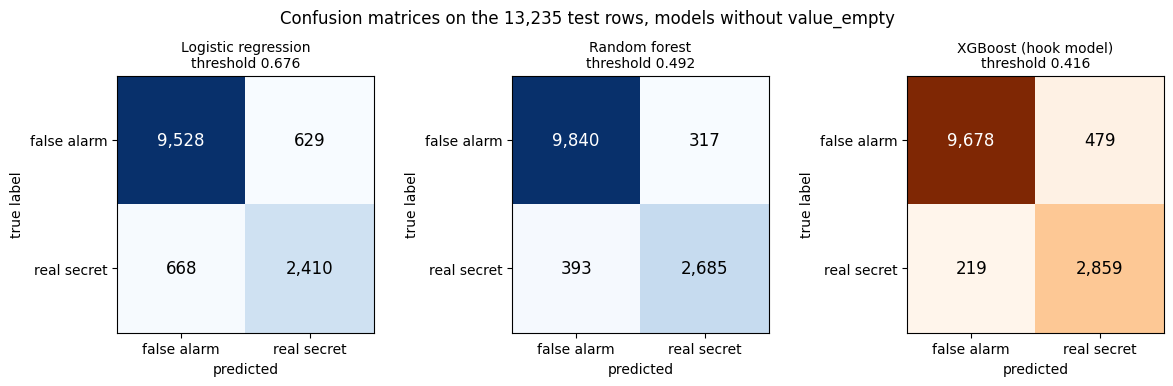

In [22]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

IMAGE_DIR = Path("..") / "images"
CM_MODELS = {
    "logreg_no_value_empty": "Logistic regression",
    "random_forest_no_value_empty": "Random forest",
    "xgboost_no_value_empty": "XGBoost (hook model)",
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, title) in zip(axes, CM_MODELS.items()):
    cm = confusion_matrix(y_test, (test_scores[name].to_numpy() >= all_thresholds[name]).astype(int))
    print(title, "| TN", cm[0, 0], "FP", cm[0, 1], "FN", cm[1, 0], "TP", cm[1, 1])
    ax.imshow(cm, cmap="Oranges" if "hook" in title else "Blues")
    for (r, c), count in np.ndenumerate(cm):
        ax.text(c, r, f"{count:,}", ha="center", va="center", fontsize=12,
                color="white" if count > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["false alarm", "real secret"])
    ax.set_yticks([0, 1], ["false alarm", "real secret"])
    ax.set_xlabel("predicted")
    ax.set_ylabel("true label")
    ax.set_title(f"{title}\nthreshold {all_thresholds[name]:.3f}", fontsize=10)
fig.suptitle("Confusion matrices on the 13,235 test rows, models without value_empty")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "13_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

The hook model misses the fewest real secrets (219, against 393 for the random forest and 668 for logistic regression). The random forest raises the fewest false alarms (317, against 479 for XGBoost and 629 for logistic regression). XGBoost trades 162 more false alarms for 174 fewer missed secrets than the random forest. For a secret scanner a missed secret is the more costly error, because it ends up in the repository history, while a false alarm only costs the developer a look at one line.

## Precision recall curves

Each curve shows the precision and recall a model reaches on the test rows as its threshold moves, and the dot marks the threshold chosen from the out of fold scores. A curve closer to the top right corner is better at every threshold. The line and path random forest is included to show how much the value features add.

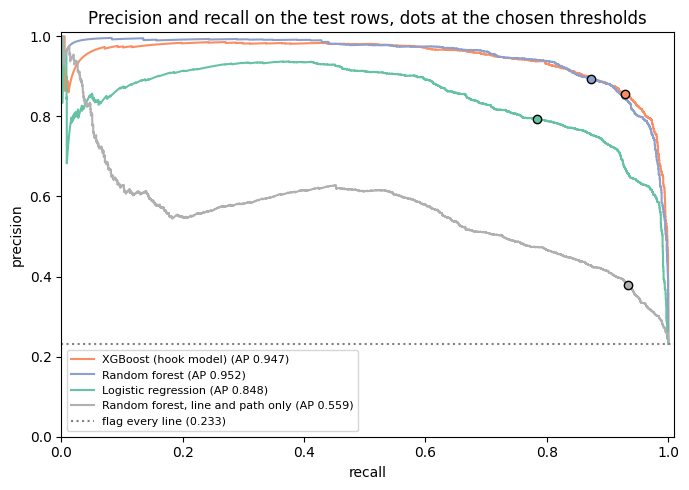

In [23]:
from sklearn.metrics import precision_recall_curve as pr_curve

PR_MODELS = {
    "xgboost_no_value_empty": ("XGBoost (hook model)", "#fc8d62"),
    "random_forest_no_value_empty": ("Random forest", "#8da0cb"),
    "logreg_no_value_empty": ("Logistic regression", "#66c2a5"),
    "random_forest_line_and_path": ("Random forest, line and path only", "#b0b0b0"),
}
fig, ax = plt.subplots(figsize=(7, 5))
for name, (label, color) in PR_MODELS.items():
    scores = test_scores[name].to_numpy()
    precision, recall, _ = pr_curve(y_test, scores)
    ax.plot(recall, precision, color=color, label=f"{label} (AP {average_precision_score(y_test, scores):.3f})")
    p, r, _ = precision_recall_at(scores, all_thresholds[name], y_test)
    ax.scatter([r], [p], color=color, edgecolor="black", zorder=3)
ax.axhline(y_test.mean(), color="grey", linestyle=":", label=f"flag every line ({y_test.mean():.3f})")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_xlim(0, 1.01)
ax.set_ylim(0, 1.01)
ax.set_title("Precision and recall on the test rows, dots at the chosen thresholds")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "14_precision_recall.png", dpi=150, bbox_inches="tight")
plt.show()

The XGBoost and random forest curves almost overlap at every threshold, so the choice between them matters less than the threshold. XGBoost stays slightly higher at the high recall end, above 0.9, where the hook works. Logistic regression is below both at almost every recall, and the line and path random forest is far below, although all models are well above the line for flagging every line (0.233). The chosen thresholds sit near the bend of each curve, so the out of fold rule picked sensible points on the test set too.

## Save the test scores

The test scores of every model go to `data/processed/test_scores.csv` with ids and labels only, no line text, for the error analysis and SHAP in `05_explain`. The file stays out of git.

In [24]:
test_scores.to_csv(TEST_SCORES_PATH, index=False, lineterminator="\n")
print("saved", TEST_SCORES_PATH.name, "with", len(test_scores), "rows and", len(all_thresholds), "score columns")

saved test_scores.csv with 13235 rows and 9 score columns
